In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn

print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

numpy       2.5.3
matplotlib  3.11.2
scikit-learn 1.9.1


In [3]:
# Plot styling - cosmetic only, safe to ignore.
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

# A fixed random generator, so your numbers match the text.
# Change the seed to see different random draws.
rng = np.random.default_rng(seed=0)

In [4]:
a = np.array([1.0, 2.0, 3.0])  # 1D: a vector of 3 numbers
b = np.array(
    [
        [1.0, 2.0, 3.0],  # 2D: 2 rows, 3 columns
        [4.0, 5.0, 6.0],
    ]
)

print("a =", a)
print("a.shape =", a.shape)  # (3,)   -> 1D, length 3
print()
print("b =")
print(b)
print("b.shape =", b.shape)  # (2, 3) -> 2 rows, 3 columns

a = [1. 2. 3.]
a.shape = (3,)

b =
[[1. 2. 3.]
 [4. 5. 6.]]
b.shape = (2, 3)


In [5]:
row = np.array([[1.0, 2.0, 3.0]])          # note the double brackets
col = np.array([[1.0], [2.0], [3.0]])

print("a   shape", a.shape,   "  <- 1D, no orientation")
print("row shape", row.shape, "<- 2D, one row")
print("col shape", col.shape, "<- 2D, one column")

# reshape(-1, 1) is the idiom for "make this a single column".
# The -1 means "work the size out for me".
print()
print("a.reshape(-1, 1) shape:", a.reshape(-1, 1).shape)

a   shape (3,)   <- 1D, no orientation
row shape (1, 3) <- 2D, one row
col shape (3, 1) <- 2D, one column

a.reshape(-1, 1) shape: (3, 1)


In [6]:
# 5 examples, 2 features each.
X = rng.normal(size=(5, 2))
print(X)
print("X.shape =", X.shape, "-> 5 examples, 2 features")

[[ 0.12573022 -0.13210486]
 [ 0.64042265  0.10490012]
 [-0.53566937  0.36159505]
 [ 1.30400005  0.94708096]
 [-0.70373524 -1.26542147]]
X.shape = (5, 2) -> 5 examples, 2 features


In [7]:
x = np.array([1.0, 2.0, 3.0, 4.0])

print("x + 10  =", x + 10)        # adds 10 to every element
print("x * 2   =", x * 2)
print("x ** 2  =", x ** 2)
print("x > 2.5 =", x > 2.5)       # elementwise comparison -> array of True/False
print()
print("np.exp(x)  =", np.exp(x))  # e to the power of each element
print("np.mean(x) =", np.mean(x)) # collapses the array to one number
print("np.sum(x)  =", np.sum(x))

x + 10  = [11. 12. 13. 14.]
x * 2   = [2. 4. 6. 8.]
x ** 2  = [ 1.  4.  9. 16.]
x > 2.5 = [False False  True  True]

np.exp(x)  = [ 2.71828183  7.3890561  20.08553692 54.59815003]
np.mean(x) = 2.5
np.sum(x)  = 10.0


Here is the same computation written both ways, so you can see the speed difference
for yourself. One million numbers, squared.

In [8]:
import time

big = rng.normal(size=1_000_000)

t0 = time.perf_counter()
result_loop = [v**2 for v in big]  # the Python way
t1 = time.perf_counter()
result_vec = big**2  # the NumPy way
t2 = time.perf_counter()

print(f"Python loop : {t1 - t0:.4f} s")
print(f"NumPy       : {t2 - t1:.4f} s")
print(f"speed-up    : {(t1 - t0) / (t2 - t1):.0f}x")

Python loop : 0.0499 s
NumPy       : 0.0006 s
speed-up    : 84x


## Matrix multiplication — the `@` operator

This is the operation at the heart of every neural network, so it is worth a minute.

Matrix multiplication combines two arrays by taking **rows of the first against
columns of the second**. For each output entry, you multiply the matching numbers
pairwise and add them up.

The shape rule is the only thing you have to remember:

```
(n, k) @ (k, m)  ->  (n, m)
      ^^^^^^^  these must match; they cancel out
```

The inner numbers must be equal, and they disappear from the result.

In [9]:
A_ = np.array([[1.0, 2.0],
               [3.0, 4.0],
               [5.0, 6.0]])      # (3, 2)

B_ = np.array([[10.0, 20.0, 30.0, 40.0],
               [50.0, 60.0, 70.0, 80.0]])   # (2, 4)

C_ = A_ @ B_

print("A_ shape", A_.shape)
print("B_ shape", B_.shape)
print("C_ shape", C_.shape, " <- (3,2) @ (2,4) -> (3,4)")
print()
print(C_)

# Check one entry by hand: top-left = row 0 of A_ against column 0 of B_
print()
print("C_[0, 0] by hand:", 1.0 * 10.0 + 2.0 * 50.0, " matches", C_[0, 0])

A_ shape (3, 2)
B_ shape (2, 4)
C_ shape (3, 4)  <- (3,2) @ (2,4) -> (3,4)

[[110. 140. 170. 200.]
 [230. 300. 370. 440.]
 [350. 460. 570. 680.]]

C_[0, 0] by hand: 110.0  matches 110.0


In [10]:
X = rng.normal(size=(5, 2))    # 5 examples, 2 features
W = rng.normal(size=(2, 3))    # 2 features in, 3 units out

Z = X @ W
print("X", X.shape, "@ W", W.shape, "-> Z", Z.shape)

X (5, 2) @ W (2, 3) -> Z (5, 3)


In [11]:
Z = rng.normal(size=(5, 3))    # 5 examples, 3 units
b = np.array([100.0, 200.0, 300.0])   # one bias per unit, shape (3,)

print("Z shape", Z.shape, "+ b shape", b.shape, "->", (Z + b).shape)
print()
print(np.round(Z + b, 2))

Z shape (5, 3) + b shape (3,) -> (5, 3)

[[ 98.57 199.36 301.69]
 [ 99.4  199.88 299.79]
 [ 97.86 198.91 299.95]
 [ 99.6  200.05 297.8 ]
 [ 98.63 199.15 298.66]]


In [12]:
# The classic broadcasting trap: an array that is "the right length" but the
# wrong orientation.
try:
    Z + np.array([1.0, 2.0, 3.0, 4.0, 5.0])     # shape (5,) vs (5, 3)
except ValueError as e:
    print("ValueError:", e)

# Fix: say explicitly that it is a column, one value per example.
print()
print("as a column:", (Z + np.array([1.0, 2.0, 3.0, 4.0, 5.0]).reshape(-1, 1)).shape)

ValueError: operands could not be broadcast together with shapes (5,3) (5,) 

as a column: (5, 3)


---
# Part 2 — A single neuron

A neuron is a small function. It takes some numbers in, and puts one number out. It
does this in two steps:

**Step 1 — weighted sum.** Multiply each input by a *weight*, add them up, then add a
*bias*:

$$z = x_1 w_1 + x_2 w_2 + \dots + b$$

The weights say how much each input matters. A large positive weight means "this
input pushes the answer up"; a large negative weight means "this input pushes it
down"; a weight near zero means "ignore this input". The bias shifts the whole thing
up or down regardless of the inputs.

**Step 2 — activation.** Pass `z` through a squashing function `a = f(z)`.

The weights and the bias are the **parameters** — the numbers that get *learned*.
Everything else about the network is fixed by us in advance.

In [13]:
def neuron(x, w, b):
    """One neuron, one example.

    x: inputs,  shape (n_features,)
    w: weights, shape (n_features,)
    b: bias,    a single number

    Returns the weighted sum z (we'll add the activation in a moment).
    """
    return x @ w + b


x = np.array([2.0, 3.0])  # one example with two features
w = np.array([0.5, -1.0])  # its two weights
b = 1.0

print("z =", neuron(x, w, b))
print("by hand:", 2.0 * 0.5 + 3.0 * -1.0 + 1.0)

z = -1.0
by hand: -1.0


In [14]:
for w_try, b_try in [(np.array([0.5, -1.0]), 1.0),
                     (np.array([10.0, 0.0]), 1.0),
                     (np.array([0.5, -1.0]), -100.0)]:
    print(f"w={w_try}, b={b_try:7.1f}  ->  z = {neuron(x, w_try, b_try):8.2f}")

w=[ 0.5 -1. ], b=    1.0  ->  z =    -1.00
w=[10.  0.], b=    1.0  ->  z =    21.00
w=[ 0.5 -1. ], b= -100.0  ->  z =  -102.00


## 2.1 Activation functions

Why not stop at the weighted sum? Because a weighted sum is a *straight line*, and
stacking straight lines on top of straight lines only ever gives you another straight
line. Without a non-linear activation function, a hundred-layer network can do no
more than a single layer can. (We will demonstrate this dramatically in notebook 2.)

The activation function bends the line. Two of them cover most of what you'll meet:

**Sigmoid** squashes anything into the range 0 to 1, which makes it readable as a
probability. Large positive input → near 1. Large negative → near 0. Zero → exactly
0.5.

**ReLU** ("rectified linear unit") is almost embarrassingly simple: negatives become
zero, positives pass through unchanged. It is the default inside modern networks
because it is fast and trains well.

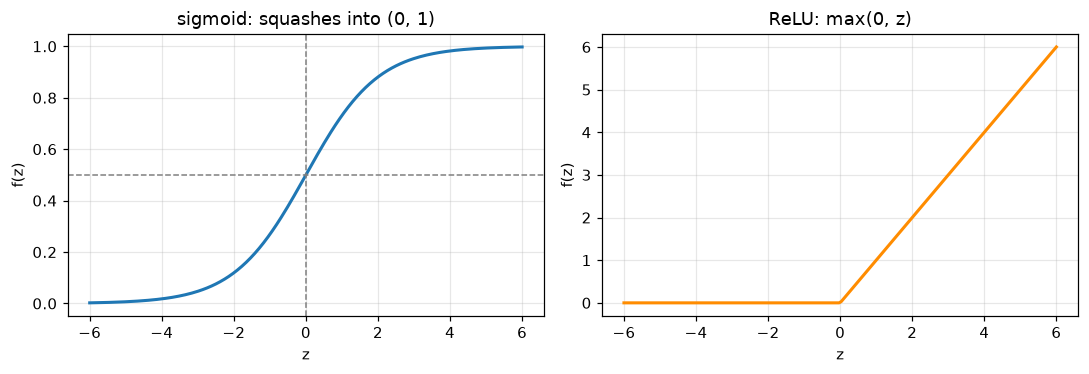

In [15]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def relu(z):
    return np.maximum(0.0, z)


zs = np.linspace(-6, 6, 200)      # 200 evenly spaced values from -6 to 6

# Two plots side by side: plt.subplots(1, 2) makes a 1-row, 2-column grid and
# hands back the figure plus an array of axes. ax.plot works like plt.plot.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(zs, sigmoid(zs), linewidth=2)
axes[0].axhline(0.5, linestyle="--", linewidth=1, color="gray")
axes[0].axvline(0.0, linestyle="--", linewidth=1, color="gray")
axes[0].set_title("sigmoid: squashes into (0, 1)")
axes[0].set_xlabel("z"); axes[0].set_ylabel("f(z)")

axes[1].plot(zs, relu(zs), linewidth=2, color="darkorange")
axes[1].set_title("ReLU: max(0, z)")
axes[1].set_xlabel("z"); axes[1].set_ylabel("f(z)")

plt.tight_layout()
plt.show()

In [16]:
# Sigmoid on some specific values, to build intuition for the numbers.
for z in [-10, -2, -1, 0, 1, 2, 10]:
    print(f"sigmoid({z:4}) = {sigmoid(z):.4f}")

sigmoid( -10) = 0.0000
sigmoid(  -2) = 0.1192
sigmoid(  -1) = 0.2689
sigmoid(   0) = 0.5000
sigmoid(   1) = 0.7311
sigmoid(   2) = 0.8808
sigmoid(  10) = 1.0000


X (200, 2)  y (200,)
labels present: [0 1]


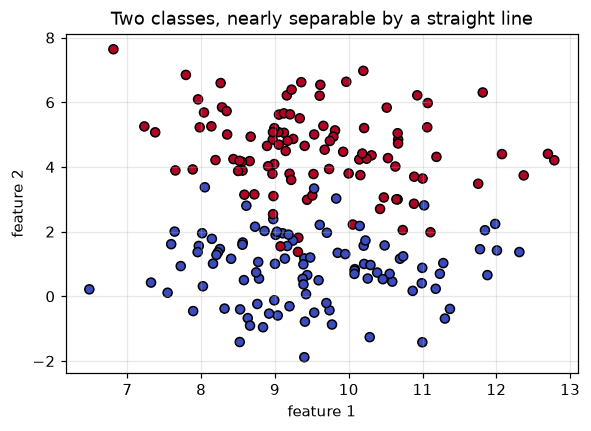

In [18]:
from sklearn.datasets import make_blobs

# Two clearly separated clusters, 2 features each.
X, y = make_blobs(
    n_samples=200, centers=2, n_features=2, cluster_std=1.2, random_state=4
)

print("X", X.shape, " y", y.shape)
print("labels present:", np.unique(y))

plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two classes, nearly separable by a straight line")
plt.show()

In [ ]:
def plot_decision_boundary(predict_fn, X, y, title="", ax=None):
    if ax is None:
        _, ax = plt.subplots()

    # 1. Work out the area to cover: the data's range, plus a small margin.
    pad = 0.5
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad

    # 2. Build a grid of points covering that area.
    # meshgrid turns two 1D ranges into two 2D coordinate arrays.
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

    # 3. Flatten the grid into a (n_points, 2) array - our usual data layout -
    # so the model can score every point in one vectorized call.
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)  # reshape back into grid form